In [1]:
#Check GPU
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. Please enable GPU in Colab.")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
#Install required libraries
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn flask

In [4]:
#Load the dataset
from datasets import load_dataset

# Load the actual Financial PhraseBank dataset
dataset = load_dataset(
    "atrost/financial_phrasebank"
)

print("Dataset loaded successfully!")
print(dataset)

print("\nAvailable splits:")
print(dataset.keys())

README.md:   0%|          | 0.00/721 [00:00<?, ?B/s]

data/train-00000-of-00001-138b53eb17a3e8(…): reconstructing file:   0%|          |  0.00B /  268kB            

data/train-00000-of-00001-138b53eb17a3e8(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-0876be41e(…): reconstructing file:   0%|          |  0.00B / 68.7kB            

data/validation-00000-of-00001-0876be41e(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-41c7ea948573445(…): reconstructing file:   0%|          |  0.00B / 82.9kB            

data/test-00000-of-00001-41c7ea948573445(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3100 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/776 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/970 [00:00<?, ? examples/s]

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['sentence', 'label'],
        num_rows: 3100
    })
    validation: Dataset({
        features: ['sentence', 'label'],
        num_rows: 776
    })
    test: Dataset({
        features: ['sentence', 'label'],
        num_rows: 970
    })
})

Available splits:
dict_keys(['train', 'validation', 'test'])


In [5]:
#Inspect the dataset
import pandas as pd

# Convert each split into a DataFrame
train_df = dataset["train"].to_pandas()
validation_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

# Combine records for dataset inspection
df = pd.concat(
    [train_df, validation_df, test_df],
    ignore_index=True
)

print("Total dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated(subset=["sentence"]).sum())

print("\nSentiment distribution:")
print(df["label"].value_counts().sort_index())

Total dataset size: (4846, 2)

Column names:
['sentence', 'label']

First 5 records:


,sentence,label
0,EBIT margin was up from 1.4 % to 5.1 % .,2
1,The current lay-offs are additional to the tem...,0
2,The acquisition is expected to take place by t...,1
3,Strong brand visibility nationally and regiona...,1
4,The end-to-end delivery combines the competenc...,1



Missing values:
sentence    0
label       0
dtype: int64

Duplicate records:
8

Sentiment distribution:
label
0     604
1    2879
2    1363
Name: count, dtype: int64


In [6]:
#Inspect the actual column values
print("Columns:", df.columns.tolist())

print("\nExample text:")
print(df.iloc[0]["sentence"])

print("\nExample sentiment label:")
print(df.iloc[0]["label"])

print("\nUnique sentiment labels:")
print(sorted(df["label"].unique()))

Columns: ['sentence', 'label']

Example text:
EBIT margin was up from 1.4 % to 5.1 % .

Example sentiment label:
2

Unique sentiment labels:
[np.int64(0), np.int64(1), np.int64(2)]


In [7]:
#Verify label mapping
from datasets import ClassLabel

features = dataset["train"].features

print(features)

label_feature = features["label"]

if isinstance(label_feature, ClassLabel):
    label_names = label_feature.names
    print("\nActual label mapping:")
    for i, name in enumerate(label_names):
        print(i, "=", name)
else:
    print("Label is not a ClassLabel feature.")

{'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'neutral', 'positive'])}

Actual label mapping:
0 = negative
1 = neutral
2 = positive


In [8]:
#Clean the data and preprocessing
# Clean training and validation data separately
train_pool_df = pd.concat(
    [train_df, validation_df],
    ignore_index=True
)

def clean_data(data):

    data = data[["sentence", "label"]].copy()

    data = data.dropna(subset=["sentence", "label"])

    data["sentence"] = data["sentence"].astype(str).str.strip()

    data = data[data["sentence"] != ""]

    data = data.drop_duplicates(subset=["sentence"])

    data["label"] = data["label"].astype(int)

    assert set(data["label"].unique()).issubset({0, 1, 2})

    return data.reset_index(drop=True)


train_pool_df = clean_data(train_pool_df)
test_df = clean_data(test_df)

# Display cleaned dataset
df = pd.concat(
    [train_pool_df, test_df],
    ignore_index=True
)

print("Training records:", len(train_pool_df))
print("Testing records:", len(test_df))
print("Total cleaned records:", len(df))

print("\nSentiment distribution:")
print(df["label"].value_counts().sort_index())

display(df.head())

Training records: 3870
Testing records: 970
Total cleaned records: 4840

Sentiment distribution:
label
0     604
1    2873
2    1363
Name: count, dtype: int64


,sentence,label
0,EBIT margin was up from 1.4 % to 5.1 % .,2
1,The current lay-offs are additional to the tem...,0
2,The acquisition is expected to take place by t...,1
3,Strong brand visibility nationally and regiona...,1
4,The end-to-end delivery combines the competenc...,1


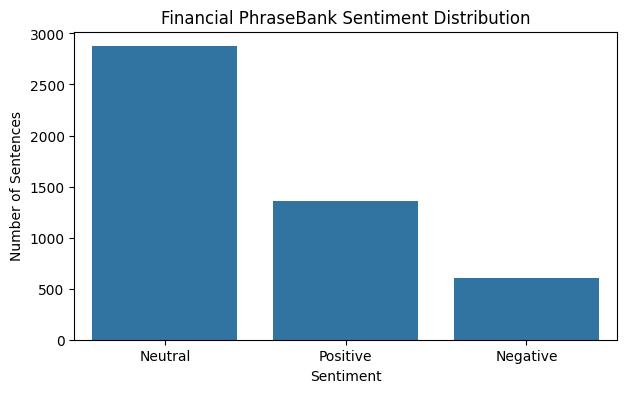

In [9]:
#Visualize Sentiment distribution chart
import matplotlib.pyplot as plt
import seaborn as sns

label_mapping = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

sentiment_counts = df["label"].map(label_mapping).value_counts()

plt.figure(figsize=(7, 4))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values)
plt.title("Financial PhraseBank Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Sentences")
plt.show()

In [10]:
#Train/Test split data
X_train = train_pool_df["sentence"].tolist()
y_train = train_pool_df["label"].tolist()

X_test = test_df["sentence"].tolist()
y_test = test_df["label"].tolist()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting sentiment distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 3870
Testing samples: 970

Training sentiment distribution:
0     479
1    2308
2    1083
Name: count, dtype: int64

Testing sentiment distribution:
0    125
1    565
2    280
Name: count, dtype: int64


In [11]:
#Load FinBERT tokenizer
#Tokenization	Converts text into tokens
from transformers import AutoTokenizer

MODEL_NAME = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizer loaded successfully.


In [12]:
#Try tokenization
sample_sentence = X_train[0]

tokens = tokenizer(
    sample_sentence,
    padding="max_length",
    truncation=True,
    max_length=128
)

print("Original sentence:")
print(sample_sentence)

print("\nInput IDs:")
print(tokens["input_ids"])

print("\nAttention mask:")
print(tokens["attention_mask"])

print("\nDecoded tokens:")
print(tokenizer.convert_ids_to_tokens(tokens["input_ids"]))

Original sentence:
EBIT margin was up from 1.4 % to 5.1 % .

Input IDs:
[101, 1041, 16313, 7785, 2001, 2039, 2013, 1015, 1012, 1018, 1003, 2000, 1019, 1012, 1015, 1003, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Attention mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Decoded tokens:
['[CLS]', 'e', '##bit', 'margin', 'was', 'up', 'from', '1', '.', '4', '

In [13]:
#Load pretrained FinBERT
#pretrained model has already learned language patterns from a large amount of text.
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

print("FinBERT model loaded.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT model loaded.


In [14]:
#Fine-tune FinBERT
#Convert data into Hugging Face format
from datasets import Dataset

train_dataset = Dataset.from_dict({
    "sentence": X_train,
    "label": y_train
})

test_dataset = Dataset.from_dict({
    "sentence": X_test,
    "label": y_test
})

print(train_dataset)
print(test_dataset)

Dataset({
    features: ['sentence', 'label'],
    num_rows: 3870
})
Dataset({
    features: ['sentence', 'label'],
    num_rows: 970
})


In [15]:
#Tokenize training and testing data
def tokenize_function(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_tokenized = train_dataset.map(
    tokenize_function,
    batched=True
)

test_tokenized = test_dataset.map(
    tokenize_function,
    batched=True
)

# Remove the original sentence column
train_tokenized = train_tokenized.remove_columns(["sentence"])
test_tokenized = test_tokenized.remove_columns(["sentence"])

# Rename label to labels, as expected by the model
train_tokenized = train_tokenized.rename_column("label", "labels")
test_tokenized = test_tokenized.rename_column("label", "labels")

# PyTorch format
train_tokenized.set_format("torch")
test_tokenized.set_format("torch")

print(train_tokenized)

Map:   0%|          | 0/3870 [00:00<?, ? examples/s]

Map:   0%|          | 0/970 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 3870
})


In [16]:
#checking the Training configuration
import torch
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./finbert_financial_sentiment",
#Epochs: how many times the model learns from the full training dataset.
    num_train_epochs=3,
#Batch size: how many records are processed at one time.
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
#Learning rate: controls how large model updates are during learning.
    learning_rate=2e-5,
    weight_decay=0.01,

    logging_steps=50,

    save_strategy="epoch",
#fp16: enables mixed-precision training on a GPU, which can save memory and improve speed.
    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

print("Training configuration created.")

Training configuration created.


In [17]:
#Train the model and Fine-tuning
from transformers import Trainer

trainer = Trainer(
    #Trainer manages the training loop, batching, optimizer updates, logging, and saving checkpoints without requiring us to write a complicated training loop ourselves.
    model=model,
    args=training_args,
    train_dataset=train_tokenized
)

trainer.train()

Step,Training Loss
50,1.334887
100,0.732871
150,0.535348
200,0.416285
250,0.432439
300,0.393417
350,0.330056
400,0.403514
450,0.316080
500,0.326236


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1452, training_loss=0.2800468235961662, metrics={'train_runtime': 176.5483, 'train_samples_per_second': 65.761, 'train_steps_per_second': 8.224, 'total_flos': 763686694955520.0, 'train_loss': 0.2800468235961662, 'epoch': 3.0})

In [18]:
#Evaluate the model
#Predict on test data
import numpy as np
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)
model.eval()

all_predictions = []
all_actual = []

for batch in trainer.get_eval_dataloader(test_tokenized):
    batch = {
        k: v.to(device)
        for k, v in batch.items()
    }

    labels = batch["labels"]

    with torch.no_grad():
        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

    predictions = torch.argmax(
        outputs.logits,
        dim=1
    )

    all_predictions.extend(predictions.cpu().numpy())
    all_actual.extend(labels.cpu().numpy())

print("Predictions completed.")
print("Total test predictions:", len(all_predictions))

Predictions completed.
Total test predictions: 970


In [19]:
#Accuracy, Precision, Recall and F1-score
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

accuracy = accuracy_score(
    all_actual,
    all_predictions
)

print("Test Accuracy:", round(accuracy, 4))

print("\nClassification Report:\n")

print(classification_report(
    all_actual,
    all_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    digits=4,
    zero_division=0
))

Test Accuracy: 0.8588

Classification Report:

              precision    recall  f1-score   support

    Negative     0.8538    0.8880    0.8706       125
     Neutral     0.8937    0.8779    0.8857       565
    Positive     0.7930    0.8071    0.8000       280

    accuracy                         0.8588       970
   macro avg     0.8468    0.8577    0.8521       970
weighted avg     0.8595    0.8588    0.8590       970



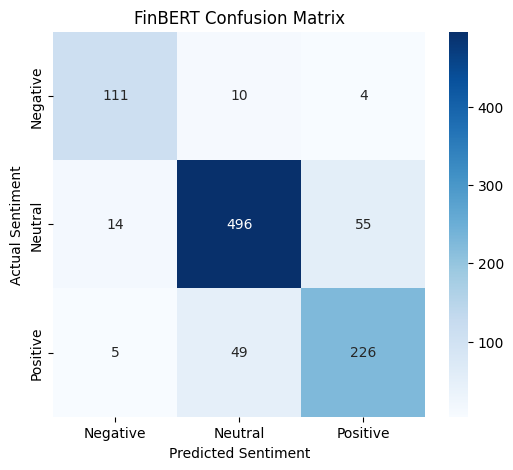

In [20]:
#Print Confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_actual,
    all_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("FinBERT Confusion Matrix")

plt.show()

In [21]:
#Test with new financial sentences
#Prediction function
import torch
import torch.nn.functional as F

sentiment_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

def predict_sentiment(text):

    model.eval()

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = F.softmax(
        outputs.logits,
        dim=1
    )

    predicted_class = torch.argmax(
        probabilities,
        dim=1
    ).item()

    confidence = probabilities[0][predicted_class].item()

    return {
        "sentence": text,
        "sentiment": sentiment_names[predicted_class],
        "confidence": round(confidence, 4)
    }

In [22]:
#Test example sentences
test_sentences = [
    "The company's profits increased significantly this year.",
    "The company reported a major loss.",
    "The company expects stable revenue next year."
]

for sentence in test_sentences:
    result = predict_sentiment(sentence)

    print("\nSentence:", result["sentence"])
    print("Sentiment:", result["sentiment"])
    print("Confidence:", result["confidence"])


Sentence: The company's profits increased significantly this year.
Sentiment: Positive
Confidence: 0.9985

Sentence: The company reported a major loss.
Sentiment: Neutral
Confidence: 0.8455

Sentence: The company expects stable revenue next year.
Sentiment: Positive
Confidence: 0.9983


In [23]:
#Interactive prediction
user_sentence = input("Enter a financial sentence: ")

result = predict_sentiment(user_sentence)

print("\nPrediction Result")
print("----------------------")
print("Sentence:", result["sentence"])
print("Sentiment:", result["sentiment"])
print("Confidence:", result["confidence"])

Enter a financial sentence: the company reported a loss last year

Prediction Result
----------------------
Sentence: the company reported a loss last year
Sentiment: Neutral
Confidence: 0.8211


In [26]:
#Save the model
import os

MODEL_SAVE_PATH = "/content/finbert_financial_sentiment_model"

os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

model.save_pretrained(MODEL_SAVE_PATH)
tokenizer.save_pretrained(MODEL_SAVE_PATH)

print("Model and tokenizer saved to:")
print(MODEL_SAVE_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved to:
/content/finbert_financial_sentiment_model
